In [1]:
import json
import os

import joblib
import numpy as np
import pandas as pd

SEED = 42

with open("../dados/metadados.json", encoding="utf-8") as f:
    meta = json.load(f)

colunas = meta["colunas_informativas"] + meta["colunas_ruido"]
alvo = meta["alvo"]

treino = pd.read_csv("../dados/treino.csv")
teste = pd.read_csv("../dados/teste.csv")

X_train, y_train = treino[colunas], treino[alvo]
X_test, y_test = teste[colunas], teste[alvo]

modelo_rf = joblib.load("../resultados/modelos/random_forest.joblib")
modelo_xgb = joblib.load("../resultados/modelos/xgboost.joblib")

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Modelos carregados:", type(modelo_rf).__name__, "e", type(modelo_xgb).__name__)

Treino: (8000, 10) | Teste: (2000, 10)
Modelos carregados: RandomForestClassifier e XGBClassifier


In [2]:
pred_rf = modelo_rf.predict_proba(X_test)[:, 1] >= 0.5
pred_xgb = modelo_xgb.predict_proba(X_test)[:, 1] >= 0.5

# Contribuintes sinalizados como Classe 1 pelos DOIS modelos
alertas = X_test.index[pred_rf & pred_xgb]
print(f"Alertas RF: {pred_rf.sum()} | Alertas XGBoost: {pred_xgb.sum()} | Em comum: {len(alertas)}")
print(f"Desses, de fato Classe 1: {int(y_test.loc[alertas].sum())}")

# Amostra aleatória (reprodutível) de 100 alertas
rng = np.random.default_rng(SEED)
indices = np.sort(rng.choice(alertas, size=min(100, len(alertas)), replace=False))
X_amostra = X_test.loc[indices]
print("Amostra:", X_amostra.shape)

os.makedirs("../resultados", exist_ok=True)
pd.Series(indices, name="indice_teste").to_csv("../resultados/amostra_indices.csv", index=False)

Alertas RF: 205 | Alertas XGBoost: 310 | Em comum: 204
Desses, de fato Classe 1: 188
Amostra: (100, 10)


In [3]:
import time

import shap


def shap_classe1(modelo, X):
    explicador = shap.TreeExplainer(modelo)
    valores = explicador.shap_values(X)
    if isinstance(valores, list):  # formato antigo: [classe 0, classe 1]
        valores = valores[1]
    valores = np.asarray(valores)
    if valores.ndim == 3:  # formato (instâncias, variáveis, classes)
        valores = valores[:, :, 1]
    base = float(np.atleast_1d(explicador.expected_value)[-1])
    return valores, base


# Random Forest (contribuições em escala de probabilidade)
t0 = time.time()
shap_rf, base_rf = shap_classe1(modelo_rf, X_amostra)
saida_rf = modelo_rf.predict_proba(X_amostra)[:, 1]
erro_rf = np.abs(shap_rf.sum(axis=1) + base_rf - saida_rf).max()
print(f"Random Forest: {time.time() - t0:.1f}s | erro máximo de aditividade: {erro_rf:.2e}")

# XGBoost (contribuições em escala de log-odds)
t0 = time.time()
shap_xgb, base_xgb = shap_classe1(modelo_xgb, X_amostra)
saida_xgb = modelo_xgb.predict(X_amostra, output_margin=True)
erro_xgb = np.abs(shap_xgb.sum(axis=1) + base_xgb - saida_xgb).max()
print(f"XGBoost: {time.time() - t0:.1f}s | erro máximo de aditividade: {erro_xgb:.2e}")

# Salva as explicações (linhas = contribuintes da amostra, colunas = variáveis)
pd.DataFrame(shap_rf, index=X_amostra.index, columns=colunas).to_csv("../resultados/shap_rf.csv")
pd.DataFrame(shap_xgb, index=X_amostra.index, columns=colunas).to_csv("../resultados/shap_xgb.csv")

# Primeira olhada: 3 variáveis mais importantes na primeira instância da amostra
for nome, valores in [("Random Forest", shap_rf), ("XGBoost", shap_xgb)]:
    top = pd.Series(valores[0], index=colunas).abs().sort_values(ascending=False).head(3)
    print(f"{nome} - 3 variáveis mais importantes na 1ª instância:", ", ".join(top.index))

c:\Users\Gabriela Eliete\Desktop\tcc_xai_fiscal\env_tcc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Random Forest: 5.1s | erro máximo de aditividade: 7.33e-15
XGBoost: 0.2s | erro máximo de aditividade: 1.05e-05
Random Forest - 3 variáveis mais importantes na 1ª instância: deducoes_fiscais, faturamento_anual, volume_notas_emitidas
XGBoost - 3 variáveis mais importantes na 1ª instância: deducoes_fiscais, faturamento_anual, imposto_declarado


In [4]:
from lime.lime_tabular import LimeTabularExplainer
from tqdm import tqdm


def explicar_lime(modelo, X, seed, num_samples=5000):
    explicador = LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=colunas,
        class_names=["Classe 0", "Classe 1"],
        mode="classification",
        discretize_continuous=False,  # pesos diretos por variável, comparáveis ao SHAP
        random_state=seed,
    )
    prever = lambda a: modelo.predict_proba(pd.DataFrame(a, columns=colunas))

    pesos = np.zeros((len(X), len(colunas)))
    r2_local = np.zeros(len(X))
    for i, linha in enumerate(tqdm(X.values, desc="LIME")):
        exp = explicador.explain_instance(
            linha, prever, labels=(1,), num_features=len(colunas), num_samples=num_samples
        )
        for j, peso in exp.as_map()[1]:
            pesos[i, j] = peso
        r2_local[i] = exp.score
    return pesos, r2_local


t0 = time.time()
lime_rf, r2_rf = explicar_lime(modelo_rf, X_amostra, SEED)
print(f"Random Forest: {time.time() - t0:.0f}s | R² local médio: {r2_rf.mean():.3f}")

t0 = time.time()
lime_xgb, r2_xgb = explicar_lime(modelo_xgb, X_amostra, SEED)
print(f"XGBoost: {time.time() - t0:.0f}s | R² local médio: {r2_xgb.mean():.3f}")

pd.DataFrame(lime_rf, index=X_amostra.index, columns=colunas).to_csv("../resultados/lime_rf.csv")
pd.DataFrame(lime_xgb, index=X_amostra.index, columns=colunas).to_csv("../resultados/lime_xgb.csv")

for nome, pesos in [("Random Forest", lime_rf), ("XGBoost", lime_xgb)]:
    top = pd.Series(pesos[0], index=colunas).abs().sort_values(ascending=False).head(3)
    print(f"{nome} - 3 variáveis mais importantes na 1ª instância:", ", ".join(top.index))

LIME: 100%|██████████| 100/100 [00:12<00:00,  7.97it/s]


Random Forest: 13s | R² local médio: 0.471


LIME: 100%|██████████| 100/100 [00:02<00:00, 39.19it/s]

XGBoost: 3s | R² local médio: 0.316
Random Forest - 3 variáveis mais importantes na 1ª instância: volume_notas_emitidas, deducoes_fiscais, movimentacao_bancaria
XGBoost - 3 variáveis mais importantes na 1ª instância: volume_notas_emitidas, deducoes_fiscais, imposto_declarado


                        SHAP - RF  LIME - RF  SHAP - XGBoost  LIME - XGBoost
faturamento_anual             4.2        2.4        6.800000             2.3
imposto_declarado             6.3        6.9        9.600000            11.0
margem_lucro_presumido        7.9        7.1        6.900000             6.9
volume_notas_emitidas        23.5       31.5       15.800000            29.7
deducoes_fiscais              8.4       15.2       11.500000            17.2
movimentacao_bancaria        26.3       24.5       27.200001            21.5
creditos_tributarios         14.9        9.7       15.200000             7.5
ruido_mercado_1               2.9        0.8        2.500000             1.8
ruido_mercado_2               2.3        0.9        2.600000             1.1
ruido_mercado_3               3.2        0.9        1.900000             1.0


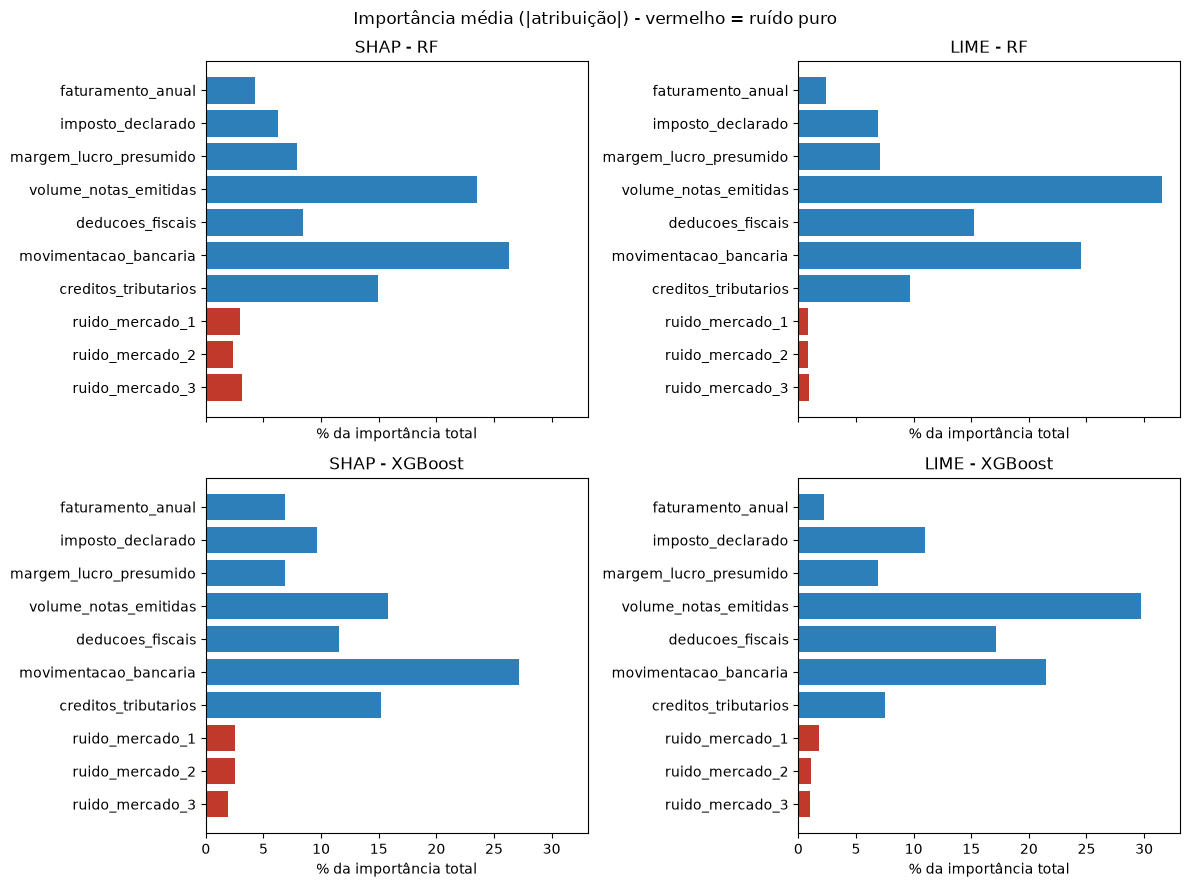

In [5]:
import matplotlib.pyplot as plt

# Salva o R² local do LIME (qualidade da aproximação linear), usado no notebook 04
pd.DataFrame(
    {"r2_lime_rf": r2_rf, "r2_lime_xgb": r2_xgb}, index=X_amostra.index
).to_csv("../resultados/lime_r2.csv")


def importancia_media(valores):
    media = np.abs(valores).mean(axis=0)
    return media / media.sum()  # proporção da importância total


tabela_imp = pd.DataFrame(
    {
        "SHAP - RF": importancia_media(shap_rf),
        "LIME - RF": importancia_media(lime_rf),
        "SHAP - XGBoost": importancia_media(shap_xgb),
        "LIME - XGBoost": importancia_media(lime_xgb),
    },
    index=colunas,
)
print((tabela_imp * 100).round(1))

cores = ["#c0392b" if c in meta["colunas_ruido"] else "#2c7fb8" for c in colunas]
fig, eixos = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for ax, (titulo, serie) in zip(eixos.ravel(), tabela_imp.items()):
    ax.barh(colunas[::-1], (serie.values * 100)[::-1], color=cores[::-1])
    ax.set_title(titulo)
    ax.set_xlabel("% da importância total")
plt.suptitle("Importância média (|atribuição|) - vermelho = ruído puro")
plt.tight_layout()
plt.savefig("../resultados/importancia_media.png", dpi=300)
plt.show()